In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT = "/content/drive/MyDrive/simuteh-2330511091"
print(os.listdir(ROOT))
print(os.listdir(f"{ROOT}/src"))

%cd {ROOT}/notebook
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak
print("OK")

Mounted at /content/drive
['requirements.txt', 'README.md', 'data', 'notebook', 'src', 'hasil', 'laporan']
['buat_dataset_sintetis.py', '__pycache__', 'utils_cv.py', 'praproses.py']
/content/drive/MyDrive/simuteh-2330511091/notebook
OK


KB kanal B   : 1.26
KB kanal G   : 0.77
KB kanal R   : 8.28
KB kanal Gray: 4.15
KB kanal H   : 6.24
KB kanal S   : 1.07
KB kanal V   : 2.35


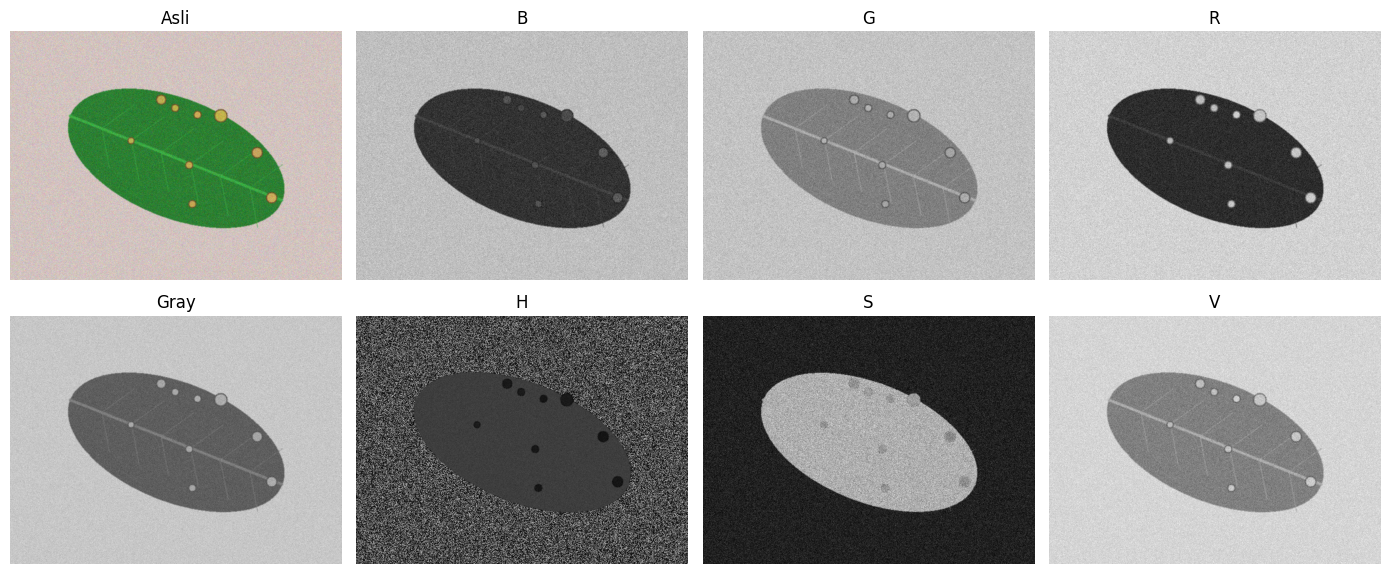

In [ ]:
from utils_cv import kontras_bercak

nama = "teh_041.png"                 # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

--- Sampling ---
fx=0.5: ukuran (240, 320), KB=5.41
fx=0.2: ukuran (96, 128), KB=4.66
fx=0.1: ukuran (48, 64), KB=2.68
fx=0.05: ukuran (24, 32), KB=0.97
--- Kuantisasi ---
k=1: 2 level, KB=5.43
k=2: 4 level, KB=5.41
k=3: 7 level, KB=2.65
k=4: 13 level, KB=3.79
k=8: 182 level, KB=4.15


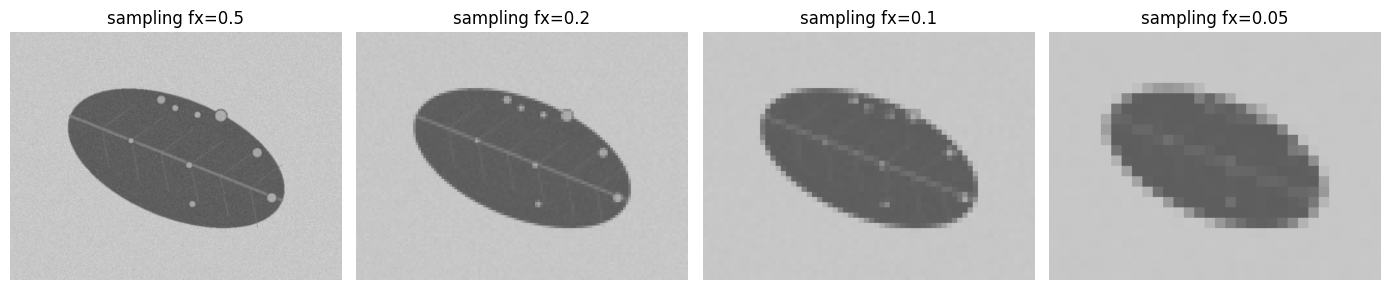

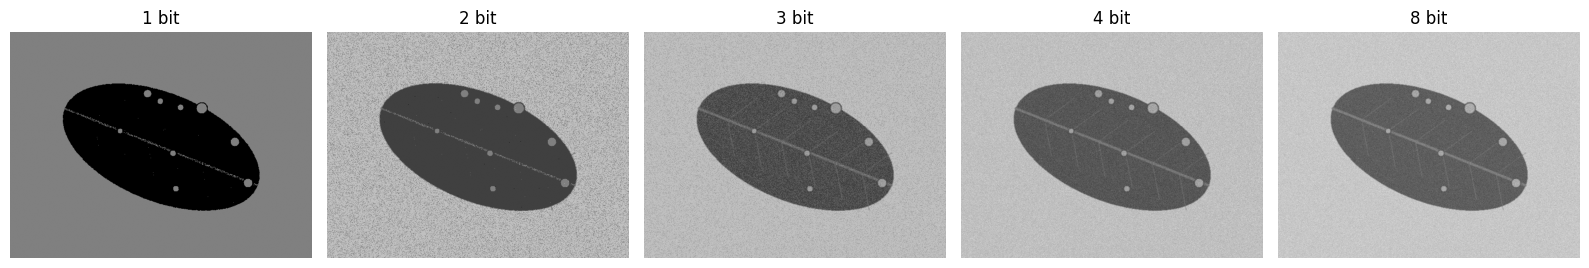

In [ ]:
print("--- Sampling ---")
hasil_sampling = []
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    kb = kontras_bercak(besar, md, mb)
    hasil_sampling.append((fx, besar))
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kb:.2f}")

print("--- Kuantisasi ---")
hasil_kuant = []
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    hasil_kuant.append((k, kuant))
    print(f"k={k}: {len(np.unique(kuant))} level, KB={kontras_bercak(kuant, md, mb):.2f}")

# tampilkan berdampingan (diminta Langkah 2.4)
tampil([besar for _, besar in hasil_sampling],
       [f"sampling fx={fx}" for fx, _ in hasil_sampling], ukuran=(14, 4))
plt.savefig("../hasil/b2_sampling.png", dpi=150); plt.show()
tampil([kuant for _, kuant in hasil_kuant],
       [f"{k} bit" for k, _ in hasil_kuant], ukuran=(16, 4))
plt.savefig("../hasil/b2_kuantisasi.png", dpi=150); plt.show()

In [ ]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"../data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

urutan = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2).reindex(urutan)
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          1.68  1.20  8.79  4.60  6.32  0.98  2.75
gelap           0.96  1.33  9.60  4.30  5.03  0.65  3.22
terang          1.74  0.87  6.64  3.72  4.88  0.66  2.07
kontras_rendah  0.79  0.60  3.68  2.22  1.72  0.18  1.55
bayangan        1.17  0.65  6.26  1.92  5.82  0.89  1.18
